# Семинар. Сети для текста: эмбеддинги, RNN, LSTM

**Курс:** «Интеллектуальный анализ текстов: от статистических моделей языка до языковых агентов». Семинар к лекции «Нейронные сети: от нейрона до seq2seq с вниманием» (модуль 2).

## О чём блокнот

Первый блокнот работал с точками на плоскости. Здесь на вход сети подаётся текст. Сначала текст представляется средним эмбеддингов его слов, и по нему работает сеть прямого распространения. Затем порядок слов учитывает рекуррентная сеть: она читает последовательность по одному элементу и хранит прочитанное в скрытом состоянии. Блокнот выполняется на процессоре примерно за две-три минуты.

| Часть | Содержание |
|---|---|
| 1 | Данные и точка отсчёта |
| 2 | Эмбеддинги на входе сети, классификатор по усреднённым эмбеддингам |
| 3 | Шаг рекуррентной сети вручную |
| 4 | Символьная языковая модель на RNN, порождение текста и температура |
| 5 | Затухание градиента |
| 6 | LSTM и GRU, задача на память |

In [1]:
import json
import random
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")
torch.set_num_threads(4)

SEED = 42
BLUE, ORANGE, MUTED, GRID = "#2a78d6", "#eb6834", "#6b7280", "#e5e7eb"
GREEN, VIOLET = "#1baf7a", "#6250d6"
# расходящаяся шкала: синий (класс 0), серый (0.5), оранжевый (класс 1)
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#cfe0f7", "#f0f0ee", "#f9d5c5", "#eb6834"])
SEQ = LinearSegmentedColormap.from_list("seq", ["#f6f9fe", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold"})


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
set_seed()
print("Готово, PyTorch", torch.__version__)

Готово, PyTorch 2.10.0+cpu


## Часть 1. Данные и точка отсчёта

Данные те же, что в блокноте о трёх классификаторах: новости Lenta.ru двух рубрик, «Экономика» (класс 0) и «Наука и техника» (класс 1). Файл `data/lenta_ru_short.jsonl` создаётся на семинаре 0.

Точкой отсчёта служит логистическая регрессия на признаках TF-IDF из лекции 2. Нейросетевую модель имеет смысл сравнивать с ней.

In [2]:
def find_data(name):
    # каталог data лежит в корне курса, он ищется вверх по дереву каталогов
    for parent in [Path.cwd()] + list(Path.cwd().parents):
        if (parent / "data" / name).exists():
            return parent / "data" / name
    raise FileNotFoundError(f"Файл data/{name} не найден. Выполните семинар 0: он загружает данные курса.")


def load_news():
    # Новости двух рубрик: 0 «Экономика», 1 «Наука и техника». Возвращает тексты и метки.
    rows = [json.loads(line) for line in open(find_data("lenta_ru_short.jsonl"), encoding="utf-8")]
    rows = [r for r in rows if r["topic"] in ("Экономика", "Наука и техника")]
    texts = [(r["title"] + ". " + r["text"]).replace("\xa0", " ") for r in rows]
    labels = np.array([1 if r["topic"] == "Наука и техника" else 0 for r in rows])
    return texts, labels


def load_titles():
    # Заголовки всех новостей файла в нижнем регистре: корпус для символьной языковой модели.
    rows = [json.loads(line) for line in open(find_data("lenta_ru_short.jsonl"), encoding="utf-8")]
    titles = [re.sub(r"\s+", " ", r["title"].replace("\xa0", " ").lower()).strip() for r in rows]
    return [t for t in titles if 15 <= len(t) <= 80]


TOKEN_RE = re.compile(r"[а-яёa-z]{2,}")


def tokenize(text):
    return TOKEN_RE.findall(text.lower())


def build_vocab(token_lists, min_count=3):
    # Слово получает номер, если встретилось не менее min_count раз. Номер 0 отдан неизвестным словам.
    counts = {}
    for toks in token_lists:
        for t in toks:
            counts[t] = counts.get(t, 0) + 1
    words = ["<unk>"] + sorted(w for w, c in counts.items() if c >= min_count)
    return {w: i for i, w in enumerate(words)}


def to_bag(token_lists, vocab):
    # Формат слоя nn.EmbeddingBag: все номера слов подряд и позиции, с которых начинается каждый текст.
    flat, offsets = [], []
    for toks in token_lists:
        offsets.append(len(flat))
        ids = [vocab.get(t, 0) for t in toks] or [0]
        flat.extend(ids)
    return torch.tensor(flat), torch.tensor(offsets)


class MeanEmbeddingClassifier(nn.Module):
    # Текст -> среднее эмбеддингов его слов -> скрытый слой с ReLU -> оценки двух классов.
    def __init__(self, vocab_size, emb_dim=32, hidden=32):
        super().__init__()
        self.emb = nn.EmbeddingBag(vocab_size, emb_dim, mode="mean")
        self.hidden = nn.Linear(emb_dim, hidden)
        self.out = nn.Linear(hidden, 2)

    def forward(self, flat, offsets):
        x = self.emb(flat, offsets)                 # (число текстов, emb_dim)
        return self.out(torch.relu(self.hidden(x)))


def train_text_classifier(model, train, y_train, test, y_test, epochs=12, lr=0.01, batch_size=64, seed=SEED):
    # train и test: списки списков номеров слов. Возвращает историю потерь и доли верных ответов по эпохам.
    set_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    y_train_t = torch.as_tensor(y_train, dtype=torch.long)

    def bag(docs):
        flat, offsets = [], []
        for d in docs:
            offsets.append(len(flat)); flat.extend(d or [0])
        return torch.tensor(flat), torch.tensor(offsets)

    test_bag = bag(test)
    history = {"loss": [], "train_acc": [], "test_acc": []}
    for _ in range(epochs):
        order = np.random.permutation(len(train))
        total, correct = 0.0, 0
        for i in range(0, len(order), batch_size):
            idx = order[i:i + batch_size]
            flat, offsets = bag([train[j] for j in idx])
            logits = model(flat, offsets)
            loss = F.cross_entropy(logits, y_train_t[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(idx); correct += (logits.argmax(1) == y_train_t[idx]).sum().item()
        with torch.no_grad():
            test_acc = (model(*test_bag).argmax(1).numpy() == np.asarray(y_test)).mean()
        history["loss"].append(total / len(train)); history["train_acc"].append(correct / len(train))
        history["test_acc"].append(float(test_acc))
    return history

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

texts, labels = load_news()
T_train, T_test, y_train, y_test = train_test_split(texts, labels, test_size=0.25, stratify=labels, random_state=SEED)
print(f"Новостей: {len(texts)}, обучающих {len(T_train)}, тестовых {len(T_test)}")
print("Пример:", T_train[0][:150], "...")

tfidf = TfidfVectorizer(token_pattern=r"[а-яёa-z]{2,}", min_df=3, sublinear_tf=True)
baseline = LogisticRegression(C=10, max_iter=2000).fit(tfidf.fit_transform(T_train), y_train)
acc_baseline = float((baseline.predict(tfidf.transform(T_test)) == y_test).mean())
print(f"Логистическая регрессия на TF-IDF: доля верных ответов на тесте {acc_baseline:.3f}")

Новостей: 1776, обучающих 1332, тестовых 444
Пример: Polaroid уволит четверть своих сотрудников. Компания Polaroid намерена в течение следующих 18 месяцев уволить 25 процентов своих сотрудников, что сост ...
Логистическая регрессия на TF-IDF: доля верных ответов на тесте 0.966


## Часть 2. Эмбеддинги на входе сети

В мешке слов каждому слову соответствует отдельный признак, и слова никак не связаны между собой. Нейросеть получает на вход **эмбеддинги**: каждому слову словаря сопоставлен вектор из $d$ чисел. Все векторы хранятся в матрице эмбеддингов $E$ размера $|V|\times d$, где $|V|$ обозначает размер словаря. Найти эмбеддинг слова означает взять строку матрицы с номером этого слова.

Матрица $E$ является частью весов сети и обучается вместе с остальными весами. Можно также взять готовые эмбеддинги word2vec из лекции 4.

Тексты имеют разную длину. Сети прямого распространения нужен вход постоянного размера. Простейшее решение: усреднить эмбеддинги всех слов текста (pooling):

$$x=\frac{1}{n}\sum_{i=1}^{n}e(w_i),\qquad h=\mathrm{ReLU}(Wx+b),\qquad \hat y=\mathrm{softmax}(Uh),$$

где $e(w_i)$ обозначает эмбеддинг слова $w_i$, $n$ число слов в тексте. Порядок слов при усреднении теряется, как и в мешке слов.

Класс `MeanEmbeddingClassifier` из ячейки выше реализует эту схему. Слой `nn.EmbeddingBag` хранит матрицу $E$ и сразу возвращает среднее эмбеддингов.

In [4]:
tok_train, tok_test = [tokenize(t) for t in T_train], [tokenize(t) for t in T_test]
vocab = build_vocab(tok_train, min_count=3)
ids_train = [[vocab.get(t, 0) for t in d] for d in tok_train]
ids_test = [[vocab.get(t, 0) for t in d] for d in tok_test]
print("Размер словаря:", len(vocab))
print("Текст как список слов:   ", tok_train[0][:8])
print("Текст как список номеров:", ids_train[0][:8])

set_seed()
clf = MeanEmbeddingClassifier(len(vocab), emb_dim=32, hidden=32)
print("\nМатрица эмбеддингов:", tuple(clf.emb.weight.shape), "| всего весов в сети:", sum(p.numel() for p in clf.parameters()))
hist = train_text_classifier(clf, ids_train, y_train, ids_test, y_test, epochs=12)
print("Доля верных ответов на тесте по эпохам:", np.round(hist["test_acc"], 3))

Размер словаря: 4562
Текст как список слов:    ['polaroid', 'уволит', 'четверть', 'своих', 'сотрудников', 'компания', 'polaroid', 'намерена']
Текст как список номеров: [217, 4147, 4423, 3557, 3808, 1683, 217, 2146]

Матрица эмбеддингов: (4562, 32) | всего весов в сети: 147106
Доля верных ответов на тесте по эпохам: [0.815 0.912 0.939 0.946 0.946 0.955 0.953 0.953 0.955 0.957 0.957 0.957]


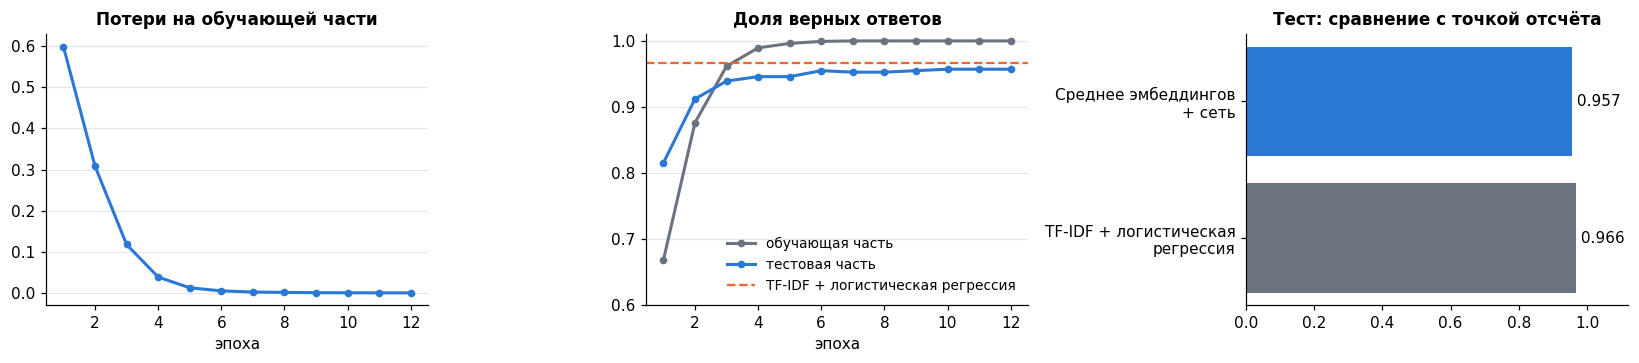

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
ep = range(1, len(hist["loss"]) + 1)
axes[0].plot(ep, hist["loss"], color=BLUE, lw=2, marker="o", ms=4); axes[0].set_title("Потери на обучающей части"); axes[0].set_xlabel("эпоха")
axes[1].plot(ep, hist["train_acc"], color=MUTED, lw=2, marker="o", ms=4, label="обучающая часть")
axes[1].plot(ep, hist["test_acc"], color=BLUE, lw=2, marker="o", ms=4, label="тестовая часть")
axes[1].axhline(acc_baseline, color=ORANGE, ls="--", lw=1.5, label="TF-IDF + логистическая регрессия")
axes[1].set_ylim(0.6, 1.01); axes[1].set_title("Доля верных ответов"); axes[1].set_xlabel("эпоха"); axes[1].legend(frameon=False, fontsize=9)
names = ["TF-IDF + логистическая\nрегрессия", "Среднее эмбеддингов\n+ сеть"]
vals = [acc_baseline, hist["test_acc"][-1]]
axes[2].barh(names, vals, color=[MUTED, BLUE])
for i, v in enumerate(vals):
    axes[2].text(v, i, f" {v:.3f}", va="center")
axes[2].set_xlim(0, 1.12); axes[2].set_title("Тест: сравнение с точкой отсчёта")
for ax in axes[:2]:
    ax.grid(axis="y", color=GRID)
fig.tight_layout()
plt.show()

**Что видно на рисунке.** Сеть за несколько эпох выходит на качество, близкое к точке отсчёта. Доля верных ответов на обучающей части доходит почти до единицы, на тестовой останавливается ниже: это обычный разрыв между обучением и тестом. Простая классическая модель на этой задаче не уступает нейросети. При полутора тысячах обучающих текстов эмбеддингам, которые учатся с нуля, не хватает данных, чтобы превзойти TF-IDF.

### Что выучили эмбеддинги

Эмбеддинги обучались только на задаче различения двух рубрик. Проекция векторов частых слов на плоскость методом главных компонент показывает, что слова одной рубрики оказались рядом.

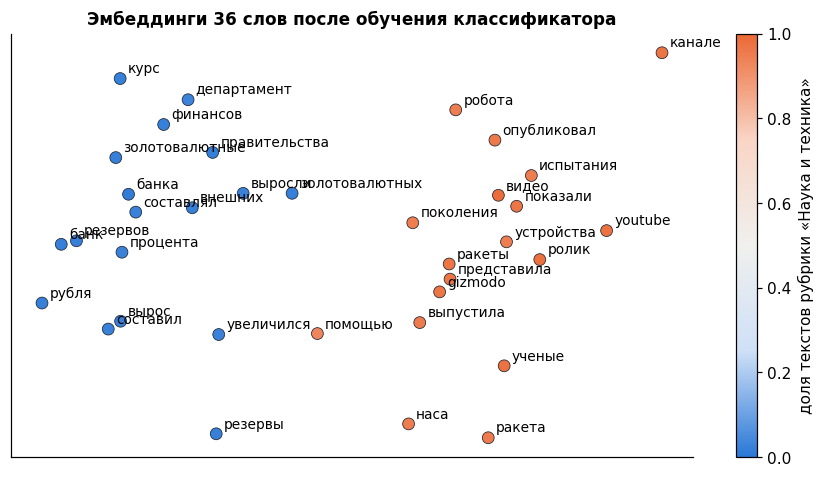

In [6]:
from sklearn.decomposition import PCA

counts = np.zeros((2, len(vocab)))
for d, cls in zip(ids_train, y_train):
    for i in set(d):
        counts[cls, i] += 1
share = (counts[1] + 1) / (counts.sum(0) + 2)                    # доля текстов рубрики «Наука и техника» среди текстов со словом
frequent = np.argsort(-counts.sum(0))[1:400]
typical = sorted(frequent, key=lambda i: share[i])
chosen = typical[:18] + typical[-18:]                            # по 18 самых характерных слов каждой рубрики
words = list(vocab)
E = clf.emb.weight.detach().numpy()
xy = PCA(n_components=2, random_state=SEED).fit_transform(E[chosen])

fig, ax = plt.subplots(figsize=(10, 5))
sc = ax.scatter(xy[:, 0], xy[:, 1], c=share[chosen], cmap=DIV, vmin=0, vmax=1, s=60, edgecolor="#1f2430", linewidth=0.5)
for (px, py), i in zip(xy, chosen):
    ax.annotate(words[i], (px, py), textcoords="offset points", xytext=(5, 4), fontsize=9)
ax.set_xticks([]); ax.set_yticks([]); ax.set_title("Эмбеддинги 36 слов после обучения классификатора")
fig.colorbar(sc, ax=ax, label="доля текстов рубрики «Наука и техника»")
plt.show()

**Что видно на рисунке.** Цвет точки показывает, в текстах какой рубрики слово встречается чаще. Слова экономической рубрики собрались в одной части плоскости, слова научной в другой. Сеть никто не учил смыслу слов: расположение векторов получилось как побочный результат обучения классификатора. Такие эмбеддинги отражают только то различие, которое требовалось для задачи.

## Часть 3. Шаг рекуррентной сети

Усреднение эмбеддингов теряет порядок слов. Рекуррентная сеть (recurrent neural network, RNN) читает последовательность по одному элементу и на каждом шаге обновляет **скрытое состояние** $h_t$:

$$h_t=\tanh\big(W\,h_{t-1}+U\,x_t+b\big),$$

где $x_t$ обозначает вектор текущего элемента (эмбеддинг слова или символа), $h_{t-1}$ состояние после предыдущего шага, $U$ матрицу весов входа, $W$ матрицу весов перехода от состояния к состоянию, $b$ вектор смещений. Начальное состояние $h_0$ нулевое. Одни и те же матрицы $U$, $W$ применяются на всех шагах, поэтому сеть обрабатывает последовательность любой длины.

Скрытое состояние служит памятью сети: в $h_t$ в сжатом виде хранится всё, что сеть прочла до шага $t$.

шаг 1: x = [1. 0.], h = [ 0.09   0.428 -0.298]
шаг 2: x = [0. 1.], h = [ 0.096  0.853 -0.075]
шаг 3: x = [1. 1.], h = [ 0.66   0.878 -0.104]
шаг 4: x = [0. 0.], h = [-0.284  0.63   0.14 ]
шаг 5: x = [ 0.5 -0.5], h = [-0.005  0.611 -0.323]

Наибольшее расхождение с nn.RNN: 5.960464477539063e-08


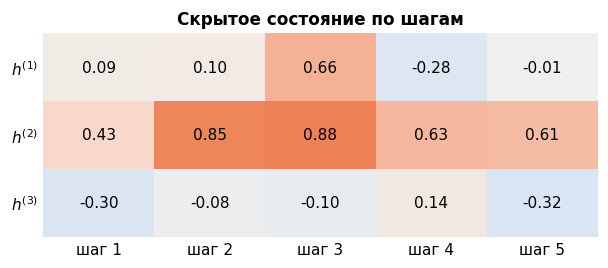

In [7]:
set_seed()
rnn = nn.RNN(input_size=2, hidden_size=3, batch_first=True)       # вход из 2 чисел, состояние из 3 чисел
U = rnn.weight_ih_l0.detach().numpy()                             # (3, 2) веса входа
W = rnn.weight_hh_l0.detach().numpy()                             # (3, 3) веса перехода
bias = (rnn.bias_ih_l0 + rnn.bias_hh_l0).detach().numpy()         # в PyTorch два вектора смещений, они складываются

xs = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0], [0.0, 0.0], [0.5, -0.5]], dtype=np.float32)   # последовательность из 5 векторов
h = np.zeros(3, dtype=np.float32)
manual = []
for t, x_t in enumerate(xs, start=1):
    h = np.tanh(W @ h + U @ x_t + bias)                           # один шаг рекуррентной сети
    manual.append(h)
    print(f"шаг {t}: x = {x_t}, h = {np.round(h, 3)}")
manual = np.array(manual)

with torch.no_grad():
    states, last = rnn(torch.tensor(xs).unsqueeze(0))
print("\nНаибольшее расхождение с nn.RNN:", float(np.abs(states[0].numpy() - manual).max()))

fig, ax = plt.subplots(figsize=(6.5, 2.4))
im = ax.imshow(manual.T, cmap=DIV, vmin=-1, vmax=1, aspect="auto")
for t in range(5):
    for j in range(3):
        ax.text(t, j, f"{manual[t, j]:.2f}", ha="center", va="center")
ax.set_xticks(range(5)); ax.set_xticklabels([f"шаг {t}" for t in range(1, 6)]); ax.set_yticks(range(3)); ax.set_yticklabels(["$h^{(1)}$", "$h^{(2)}$", "$h^{(3)}$"])
ax.set_title("Скрытое состояние по шагам"); ax.spines[["left", "bottom"]].set_visible(False); ax.tick_params(length=0)
plt.show()

**Что видно на рисунке.** Столбец показывает скрытое состояние после очередного шага. Расчёт по формуле совпал с результатом слоя `nn.RNN` до ошибки округления. На шаге 4 вход нулевой, и состояние при этом не обнулилось: оно вычислено из состояния шага 3. Так информация о ранних элементах переходит на поздние шаги.

## Часть 4. Символьная языковая модель на RNN

Языковая модель предсказывает следующий элемент текста по предыдущим (лекция 1). В n-граммной модели контекст ограничен $n-1$ элементами. Рекуррентная сеть использует весь прочитанный текст через скрытое состояние:

$$h_t=\tanh(W\,h_{t-1}+U\,e(w_t)+b),\qquad \hat y_t=\mathrm{softmax}(V\,h_t),$$

где $e(w_t)$ обозначает эмбеддинг текущего элемента, $V$ матрицу выходного слоя, $\hat y_t$ распределение вероятностей следующего элемента.

При обучении на вход подаётся текст, правильным ответом на каждом шаге служит следующий элемент того же текста. Потери равны средней кросс-энтропии по шагам. Разметка не нужна: текст сам содержит ответы.

Здесь элементами служат символы. Корпус состоит из заголовков новостей в нижнем регистре. К каждому заголовку добавлены служебные символы начала и конца.

In [8]:
PAD, BOS, EOS = 0, 1, 2      # служебные символы: заполнитель, начало и конец последовательности


class CharVocab:
    def __init__(self, texts):
        self.chars = ["<pad>", "<bos>", "<eos>"] + sorted({c for t in texts for c in t})
        self.index = {c: i for i, c in enumerate(self.chars)}

    def __len__(self):
        return len(self.chars)

    def encode(self, text):
        return [self.index[c] for c in text if c in self.index]

    def decode(self, ids):
        return "".join(self.chars[i] for i in ids if i > EOS)


def pad_batch(seqs):
    # Выравнивает последовательности номеров до общей длины заполнителем PAD.
    out = torch.full((len(seqs), max(len(s) for s in seqs)), PAD, dtype=torch.long)
    for i, s in enumerate(seqs):
        out[i, :len(s)] = torch.tensor(s)
    return out


class CharLM(nn.Module):
    # Символьная языковая модель: эмбеддинг символа -> рекуррентный слой -> оценки следующего символа.
    def __init__(self, vocab_size, emb_dim=32, hidden=128, cell="rnn"):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.rnn = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell](emb_dim, hidden, batch_first=True)
        self.out = nn.Linear(hidden, vocab_size)

    def forward(self, x, state=None):
        h, state = self.rnn(self.emb(x), state)
        return self.out(h), state


def lm_batches(encoded, batch_size, shuffle=True):
    order = np.random.permutation(len(encoded)) if shuffle else np.arange(len(encoded))
    for i in range(0, len(order), batch_size):
        seqs = [[BOS] + encoded[j] + [EOS] for j in order[i:i + batch_size]]
        batch = pad_batch(seqs)
        yield batch[:, :-1], batch[:, 1:]            # вход и тот же текст со сдвигом на один символ


def lm_perplexity(model, encoded, batch_size=128):
    # Перплексия на символ: экспонента средней кросс-энтропии.
    total, count = 0.0, 0
    with torch.no_grad():
        for x, y in lm_batches(encoded, batch_size, shuffle=False):
            logits, _ = model(x)
            total += F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), ignore_index=PAD, reduction="sum").item()
            count += (y != PAD).sum().item()
    return float(np.exp(total / count))


def train_char_lm(model, train, valid, epochs=6, lr=3e-3, batch_size=64, seed=SEED, verbose=True):
    set_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(epochs):
        for x, y in lm_batches(train, batch_size):
            logits, _ = model(x)
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), ignore_index=PAD)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)      # ограничение нормы градиента
            opt.step()
        history.append(lm_perplexity(model, valid))
        if verbose:
            print(f"эпоха {epoch + 1}: перплексия на отложенных заголовках {history[-1]:.2f}")
    return history


def generate(model, vocab, prefix="", temperature=1.0, max_len=70, seed=None):
    # Порождение по одному символу: распределение следующего символа делится на температуру и из него берётся выборка.
    if seed is not None:
        torch.manual_seed(seed)
    ids = [BOS] + vocab.encode(prefix)
    x = torch.tensor([ids])
    out, state = model(x)
    result = list(ids[1:])
    for _ in range(max_len):
        probs = F.softmax(out[0, -1] / temperature, dim=0)
        nxt = int(torch.multinomial(probs, 1))
        if nxt == EOS:
            break
        result.append(nxt)
        out, state = model(torch.tensor([[nxt]]), state)
    return vocab.decode(result)

In [9]:
titles = load_titles()
cvocab = CharVocab(titles)
encoded = [cvocab.encode(t) for t in titles]
order = np.random.RandomState(SEED).permutation(len(encoded))
n_train = int(0.9 * len(encoded))
lm_train, lm_valid = [encoded[i] for i in order[:n_train]], [encoded[i] for i in order[n_train:]]
print(f"Заголовков: {len(titles)}, символов в словаре: {len(cvocab)}, обучающих заголовков {len(lm_train)}, отложенных {len(lm_valid)}")
print("Примеры:", titles[:3])
x_demo, y_demo = next(lm_batches(lm_train[:1], 1, shuffle=False))
print("Вход:  ", [cvocab.chars[i] for i in x_demo[0][:12].tolist()])
print("Ответ: ", [cvocab.chars[i] for i in y_demo[0][:12].tolist()])


def count_perplexity(order_n):
    # Точка отсчёта: символьная n-граммная модель со сглаживанием Лапласа (order_n = 1 или 2).
    V = len(cvocab)
    counts = np.ones((V, V)) if order_n == 2 else np.ones((1, V))
    for s in lm_train:
        seq = [BOS] + s + [EOS]
        for a, c in zip(seq[:-1], seq[1:]):
            counts[a if order_n == 2 else 0, c] += 1
    probs = counts / counts.sum(1, keepdims=True)
    logp, n = 0.0, 0
    for s in lm_valid:
        seq = [BOS] + s + [EOS]
        for a, c in zip(seq[:-1], seq[1:]):
            logp += np.log(probs[a if order_n == 2 else 0, c]); n += 1
    return float(np.exp(-logp / n))


ppl_uni, ppl_bi = count_perplexity(1), count_perplexity(2)
print(f"\nПерплексия на символ: униграммная модель {ppl_uni:.2f}, биграммная модель {ppl_bi:.2f}")

Заголовков: 4445, символов в словаре: 91, обучающих заголовков 4000, отложенных 445
Примеры: ['торговля в сша начинает оживляться', 'олег меньшиков оказался в больнице', 'вышел второй трейлер «чудо-женщины» с галь гадот']
Вход:   ['<bos>', 'с', 'ш', 'а', ',', ' ', 'я', 'п', 'о', 'н', 'и', 'я']
Ответ:  ['с', 'ш', 'а', ',', ' ', 'я', 'п', 'о', 'н', 'и', 'я', ' ']

Перплексия на символ: униграммная модель 27.16, биграммная модель 14.76


Перплексия на отложенных заголовках по эпохам: [15.72 12.5  11.04 10.01  9.3   8.81  8.4   8.12  7.89  7.67  7.52  7.41
  7.31  7.17  7.08  7.    6.95  6.9   6.83  6.78]


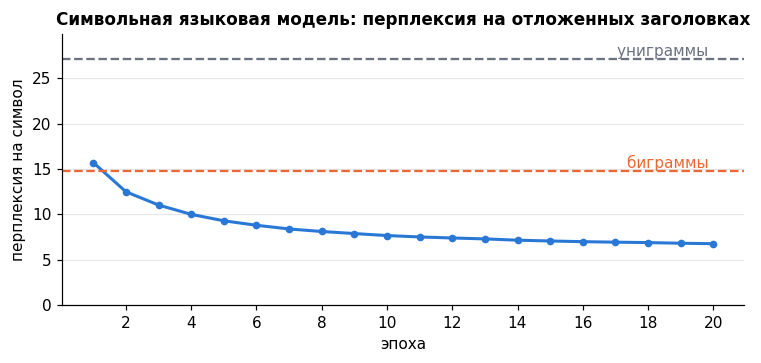

In [10]:
set_seed()
char_lm = CharLM(len(cvocab), emb_dim=32, hidden=128, cell="rnn")
lm_history = train_char_lm(char_lm, lm_train, lm_valid, epochs=20, verbose=False)
print("Перплексия на отложенных заголовках по эпохам:", np.round(lm_history, 2))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(range(1, len(lm_history) + 1), lm_history, color=BLUE, lw=2, marker="o", ms=4, label="RNN")
ax.axhline(ppl_uni, color=MUTED, ls="--", lw=1.5); ax.text(len(lm_history), ppl_uni, "униграммы ", ha="right", va="bottom", color=MUTED)
ax.axhline(ppl_bi, color=ORANGE, ls="--", lw=1.5); ax.text(len(lm_history), ppl_bi, "биграммы ", ha="right", va="bottom", color=ORANGE)
ax.set_xlabel("эпоха"); ax.set_ylabel("перплексия на символ"); ax.set_title("Символьная языковая модель: перплексия на отложенных заголовках")
ax.set_xticks(range(2, len(lm_history) + 1, 2)); ax.grid(axis="y", color=GRID); ax.set_ylim(0, ppl_uni * 1.1)
plt.show()

**Что видно на рисунке.** Перплексия показывает, между сколькими равновероятными символами модель в среднем выбирает на каждом шаге. Униграммная модель знает только частоты символов. Биграммная учитывает один предыдущий символ. Рекуррентная сеть после нескольких эпох опускается ниже биграммной модели: скрытое состояние даёт ей контекст длиннее одного символа.

### Порождение текста и температура

Обученная модель порождает текст по одному символу. На каждом шаге она выдаёт распределение следующего символа, из него берётся случайная выборка, и выбранный символ подаётся на вход следующего шага. Перед выборкой оценки делят на **температуру** $T$:

$$p_i=\mathrm{softmax}(z/T)_i.$$

При $T<1$ распределение заостряется, и модель чаще выбирает самые вероятные символы. При $T>1$ распределение выравнивается, и в текст попадают маловероятные символы.

T = 0.3
     в москве подарил подрали с соперника в проиграл в серейлер проведит пр
     в москве выставил на видео
     россия после болельщик по воставил стал в матче на видео
T = 0.7
     восо рекорд опредотара слование обогратиль проевто выстоетрии в кара м
     вышел трейлер победила за 50 миллиарсеров поставой доголжента забила в
     узерохла-2008: показался вышел выпустили тренистения лучший свой росси
T = 1.0
     boeing суперовке отордл лось перед интерном средила на чехопский про м
     вышелленые видео
     узерохла-2008: покадил кореча игрые марком за америккико»
T = 1.5
     boms огляви опклоно. duky сборг
     вышелленые видуагон счю
     узачахла-2008: aurshecs w oaycuergac

Продолжение заданного начала при T = 0.7:
     ученые автогонов созданы
     цены на проверию
     в россии во время проялионов швен


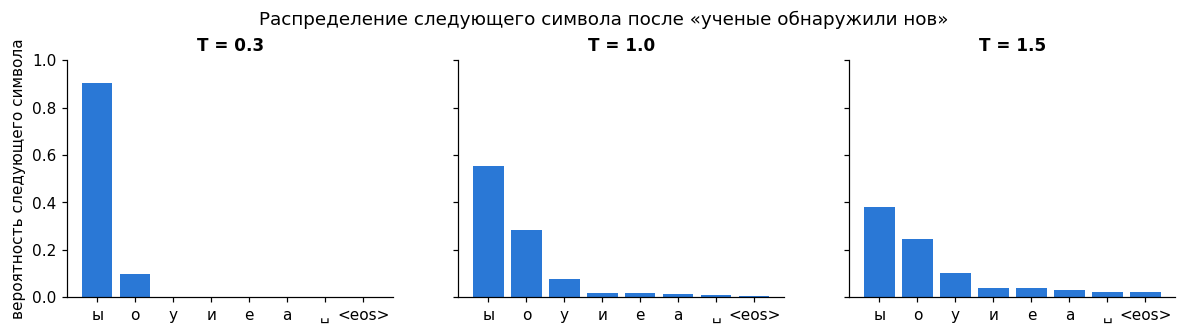

In [11]:
for T in (0.3, 0.7, 1.0, 1.5):
    print(f"T = {T}")
    for s in range(3):
        print("    ", generate(char_lm, cvocab, prefix="", temperature=T, seed=10 + s))
print("\nПродолжение заданного начала при T = 0.7:")
for k, prefix in enumerate(("ученые ", "цены на ", "в россии ")):
    print("    ", generate(char_lm, cvocab, prefix=prefix, temperature=0.7, seed=20 + k))

prefix = "ученые обнаружили нов"
with torch.no_grad():
    logits, _ = char_lm(torch.tensor([[BOS] + cvocab.encode(prefix)]))
logits = logits[0, -1]
top = torch.argsort(logits, descending=True)[:8]
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8), sharey=True)
for ax, T in zip(axes, (0.3, 1.0, 1.5)):
    p = F.softmax(logits / T, dim=0)
    ax.bar([("␣" if cvocab.chars[i] == " " else cvocab.chars[i]) for i in top.tolist()], p[top].numpy(), color=BLUE)
    ax.set_title(f"T = {T}"); ax.set_ylim(0, 1)
axes[0].set_ylabel("вероятность следующего символа")
fig.suptitle(f"Распределение следующего символа после «{prefix}»", y=1.04)
plt.show()

**Что видно на рисунке и в текстах.** При $T=0.3$ почти вся вероятность сосредоточена на одном-двух символах, тексты получаются однообразными и состоят из частых сочетаний. При $T=1.5$ распределение выровнено, и в текстах появляются несуществующие слова. Значения около 0.7 дают промежуточный результат. Модель небольшая и обучалась меньше минуты, поэтому настоящих заголовков она не пишет. При этом она усвоила длину слов, типичные окончания и частые слова: всё это получено из одного сигнала, предсказания следующего символа.

## Часть 5. Затухание градиента

При обучении рекуррентной сети ошибка с последнего шага передаётся назад по времени ко всем предыдущим шагам (backpropagation through time). На каждом шаге назад градиент умножается на матрицу $W$ и на производную tanh, которая не превосходит единицы. Если эти множители в среднем меньше единицы, после многих шагов градиент становится исчезающе малым. Ранние элементы последовательности перестают влиять на обучение, и сеть не может выучить далёкие зависимости. Это называется **затуханием градиента** (vanishing gradient).

Опыт: сеть читает случайную последовательность из 40 векторов. Измеряется норма градиента выхода последнего шага по входу на каждом шаге. Веса случайные, сеть не обучалась. Результат усреднён по 30 запускам. Сравниваются простая RNN и два варианта сети LSTM, устройство которой разобрано в части 6.

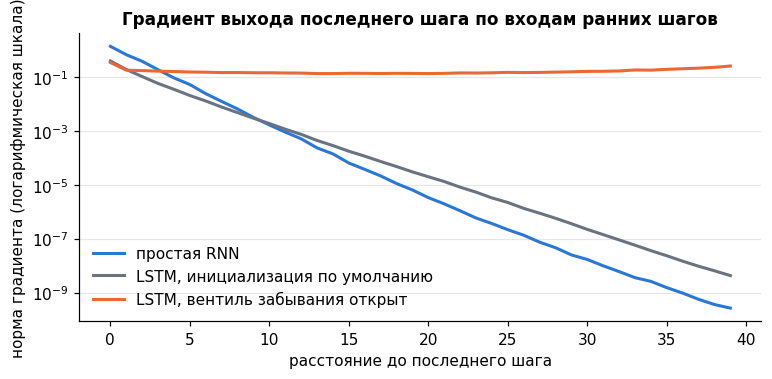

Расстояние 20 шагов: RNN 3.3e-06, LSTM по умолчанию 2.0e-05, LSTM с открытым вентилем 1.3e-01
Расстояние 39 шагов: RNN 2.7e-10, LSTM по умолчанию 4.3e-09, LSTM с открытым вентилем 2.5e-01


In [12]:
def gradient_by_distance(cell, length=40, n_runs=30):
    norms = np.zeros(length)
    for run in range(n_runs):
        torch.manual_seed(run)
        net = nn.RNN(8, 32, batch_first=True) if cell == "rnn" else nn.LSTM(8, 32, batch_first=True)
        if cell == "lstm_open":                               # смещение вентиля забывания +3: вентиль открыт
            net.bias_ih_l0.data[32:64] = 3.0
            net.bias_hh_l0.data[32:64] = 0.0
        x = torch.randn(1, length, 8, requires_grad=True)
        out, _ = net(x)
        out[0, -1].sum().backward()                           # градиент выхода последнего шага
        norms += x.grad[0].norm(dim=1).numpy()                # норма градиента по входу каждого шага
    return norms / n_runs


grads = {cell: gradient_by_distance(cell) for cell in ("rnn", "lstm", "lstm_open")}
dist = np.arange(40)[::-1]                                    # расстояние от шага до конца последовательности
fig, ax = plt.subplots(figsize=(8, 3.4))
for cell, col, name in [("rnn", BLUE, "простая RNN"), ("lstm", MUTED, "LSTM, инициализация по умолчанию"),
                        ("lstm_open", ORANGE, "LSTM, вентиль забывания открыт")]:
    ax.semilogy(dist, grads[cell], color=col, lw=2, label=name)
ax.set_xlabel("расстояние до последнего шага"); ax.set_ylabel("норма градиента (логарифмическая шкала)")
ax.set_title("Градиент выхода последнего шага по входам ранних шагов"); ax.legend(frameon=False); ax.grid(axis="y", color=GRID)
plt.show()
for d in (20, 39):
    print(f"Расстояние {d} шагов: " + ", ".join(f"{name} {grads[cell][39 - d]:.1e}" for cell, name in
                                                 [("rnn", "RNN"), ("lstm", "LSTM по умолчанию"), ("lstm_open", "LSTM с открытым вентилем")]))

**Что видно на рисунке.** Шкала по вертикали логарифмическая. У простой RNN норма градиента падает почти по прямой, то есть экспоненциально: каждый шаг назад уменьшает её в одно и то же число раз. На расстоянии 39 шагов от градиента остаётся около $10^{-10}$ исходной величины. У LSTM с инициализацией по умолчанию градиент затухает почти так же быстро. У LSTM с открытым вентилем забывания он на всём отрезке остаётся одного порядка. Сама по себе архитектура LSTM затухание не устраняет: важно, чтобы вентиль забывания пропускал содержимое ячейки.

## Часть 6. LSTM и GRU

Сеть LSTM (long short-term memory, Hochreiter, Schmidhuber, 1997) добавляет к скрытому состоянию $h_t$ отдельный вектор памяти $c_t$, ячейку. Тремя **вентилями** управляют маленькие слои с сигмоидой, их выходы лежат между 0 и 1 и умножаются на данные поэлементно:

- вентиль забывания $f_t$ решает, какую часть старой памяти сохранить,
- вентиль входа $i_t$ решает, какую часть новой информации $g_t$ записать,
- вентиль выхода $o_t$ решает, какую часть памяти показать в скрытом состоянии.

$$c_t=f_t\odot c_{t-1}+i_t\odot g_t,\qquad h_t=o_t\odot\tanh(c_t),$$

где $\odot$ обозначает поэлементное умножение. Память обновляется сложением. Если вентиль забывания близок к 1, содержимое ячейки переходит на следующий шаг почти без изменений, и градиент по этому пути не затухает.

Сеть GRU (gated recurrent unit, Cho и др., 2014) устроена проще: у неё два вентиля и нет отдельной ячейки. По качеству она обычно близка к LSTM.

### Задача на память

Последовательность состоит из одного значащего символа в начале (один из восьми) и случайных символов-заполнителей после него. Сеть читает всю последовательность и в конце должна назвать первый символ. Случайное угадывание даёт долю верных ответов $1/8=0.125$. Чем длиннее последовательность, тем дольше нужно хранить первый символ.

Четыре модели различаются только рекуррентным слоем: простая RNN, GRU и два варианта LSTM. Первый вариант LSTM использует инициализацию PyTorch по умолчанию. Во втором смещение вентиля забывания равно $+3$: тогда $\sigma(3)=0.95$, вентиль в начале обучения открыт, и ячейка переносит содержимое со шага на шаг почти без потерь. Каждая модель обучается 1000 шагов на новых случайных примерах.

In [13]:
N_CLASSES, N_FILL = 8, 8      # восемь значащих символов и восемь символов-заполнителей


def memory_batch(length, batch_size):
    # Первый символ случайный из N_CLASSES, остальные length-1 символов случайные заполнители.
    # Ответ: первый символ. Сеть должна пронести его через всю последовательность.
    first = torch.randint(0, N_CLASSES, (batch_size,))
    x = torch.randint(N_CLASSES, N_CLASSES + N_FILL, (batch_size, length))
    x[:, 0] = first
    return x, first


class SequenceClassifier(nn.Module):
    # Эмбеддинг символа -> рекуррентный слой -> класс по последнему скрытому состоянию.
    # cell: "rnn", "gru", "lstm" (инициализация PyTorch по умолчанию) или "lstm_open" (вентиль забывания открыт).
    def __init__(self, cell="rnn", emb_dim=16, hidden=32):
        super().__init__()
        self.emb = nn.Embedding(N_CLASSES + N_FILL, emb_dim)
        layer = {"rnn": nn.RNN, "lstm": nn.LSTM, "lstm_open": nn.LSTM, "gru": nn.GRU}[cell]
        self.rnn = layer(emb_dim, hidden, batch_first=True)
        if cell == "lstm_open":
            open_forget_gate(self.rnn, hidden)
        self.out = nn.Linear(hidden, N_CLASSES)

    def forward(self, x):
        h, _ = self.rnn(self.emb(x))
        return self.out(h[:, -1])


def open_forget_gate(lstm, hidden, value=3.0):
    # Смещение вентиля забывания равно +3: sigma(3) = 0.95, поэтому в начале обучения ячейка
    # переносит своё содержимое на следующий шаг почти без потерь, и градиент проходит вдоль ячейки.
    # В PyTorch смещения четырёх вентилей лежат подряд: вход, забывание, кандидат, выход.
    lstm.bias_ih_l0.data[hidden:2 * hidden] = value
    lstm.bias_hh_l0.data[hidden:2 * hidden] = 0.0


def train_memory(cell, length, steps=400, batch_size=64, lr=3e-3, seed=SEED):
    # Обучает модель на задаче «запомнить первый символ» и возвращает долю верных ответов на 2000 новых примерах.
    set_seed(seed)
    model = SequenceClassifier(cell)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(steps):
        x, y = memory_batch(length, batch_size)
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    with torch.no_grad():
        x, y = memory_batch(length, 2000)
        return float((model(x).argmax(1) == y).float().mean())

Пример входа (номера символов, первые 8 номеров значащие): [[4, 12, 15, 10, 13, 13, 12, 11, 13, 14], [7, 12, 15, 9, 11, 8, 13, 15, 15, 12]] ответы: [4, 7]
            rnn   lstm  lstm_open   gru
длина 5   1.000  1.000        1.0  1.00
длина 10  0.254  1.000        1.0  1.00
длина 20  0.117  0.131        1.0  1.00
длина 40  0.133  0.121        1.0  0.13


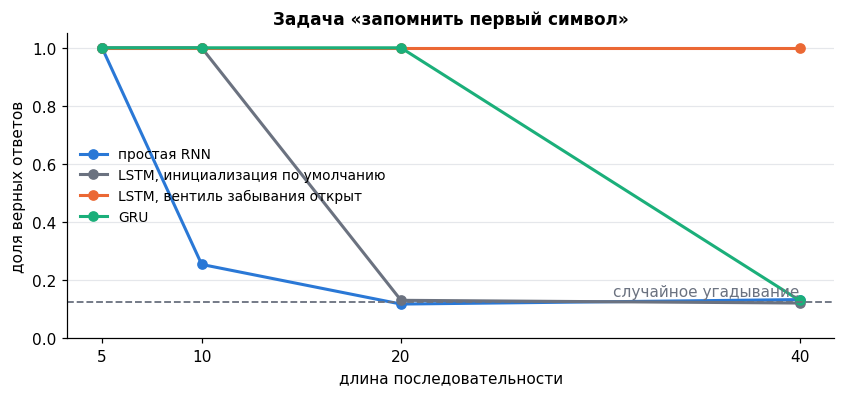

In [14]:
x_demo, y_demo = memory_batch(length=10, batch_size=2)
print("Пример входа (номера символов, первые 8 номеров значащие):", x_demo.tolist(), "ответы:", y_demo.tolist())

lengths = [5, 10, 20, 40]
CELLS = [("rnn", BLUE, "простая RNN"), ("lstm", MUTED, "LSTM, инициализация по умолчанию"),
         ("lstm_open", ORANGE, "LSTM, вентиль забывания открыт"), ("gru", GREEN, "GRU")]
memory_results = {cell: [train_memory(cell, L, steps=1000, lr=3e-3) for L in lengths] for cell, _, _ in CELLS}
print(pd.DataFrame(memory_results, index=[f"длина {L}" for L in lengths]).round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 3.6))
for cell, col, name in CELLS:
    ax.plot(lengths, memory_results[cell], color=col, lw=2, marker="o", label=name)
ax.axhline(1 / N_CLASSES, color=MUTED, ls="--", lw=1.2); ax.text(lengths[-1], 1 / N_CLASSES + 0.02, "случайное угадывание", ha="right", color=MUTED)
ax.set_xticks(lengths); ax.set_ylim(0, 1.05); ax.set_xlabel("длина последовательности"); ax.set_ylabel("доля верных ответов")
ax.set_title("Задача «запомнить первый символ»"); ax.legend(frameon=False, loc="center left", fontsize=9); ax.grid(axis="y", color=GRID)
plt.show()

**Что видно на рисунке.** Пунктир показывает уровень случайного угадывания.

- Простая RNN решает задачу только при длине 5. Уже при длине 10 доля верных ответов падает до четверти, при длине 20 и больше сеть отвечает наугад.
- LSTM с инициализацией по умолчанию держится до длины 10 и при длине 20 тоже отвечает наугад.
- LSTM с открытым вентилем забывания решает задачу при всех длинах, включая 40.
- GRU справляется с длиной 20 и не справляется с длиной 40.

Опыт согласуется с измерением градиента из части 5. Сеть учится хранить первый символ только тогда, когда сигнал об ошибке доходит от последнего шага до первого. При открытом вентиле забывания он доходит, и LSTM за те же 1000 шагов выучивает зависимость длиной в 40 шагов. Результаты получены при одном наборе настроек (скрытое состояние из 32 чисел, 1000 шагов обучения). При более долгом обучении границы сдвигаются, порядок моделей остаётся тем же.

## Итог

- Нейросеть получает слова в виде эмбеддингов: строк обучаемой матрицы.
- Среднее эмбеддингов даёт вектор текста постоянного размера. Такой классификатор прост и теряет порядок слов.
- Рекуррентная сеть читает последовательность по шагам и хранит прочитанное в скрытом состоянии. Одни и те же веса применяются на каждом шаге.
- Языковая модель на RNN предсказывает следующий элемент по всему прочитанному тексту и обучается на самом тексте без разметки.
- Температура управляет разнообразием порождаемого текста.
- В простой RNN градиент затухает с расстоянием, и далёкие зависимости не выучиваются. LSTM и GRU ослабляют затухание с помощью вентилей.

Следующий блокнот соединяет две рекуррентные сети в модель «последовательность в последовательность» и добавляет механизм внимания.